# Data quality (2022-2023)

Goal: understand the sensor data before writing cleaning rules (EDA steps 0-4).

Each section: question → code → what we found → decision.

Data: data/interim/*.parquet, **2022-2023 only**. 2024 is the locked test year.

In [ ]:
import calendar
from datetime import date, datetime, time

import matplotlib.pyplot as plt
import polars as pl

from madrid_congestion.config import DST_ROWS, EDA_YEARS, FIGURES_DIR, INTERIM_DATA_DIR, SAMPLES_FULL, SLOT, URB
 
EDA_MONTHS = [f"{year}-{month:02d}" for year in EDA_YEARS for month in range(1, 13)]
SLOTS_PER_DAY = 96
print(len(EDA_MONTHS), EDA_MONTHS[0], EDA_MONTHS[-1], INTERIM_DATA_DIR)

24 2022-01 2023-12 E:\Madrid-traffic-ageing_Advanced project\madrid-congestion\data\interim


## Overview of the data

In [24]:
OVERVIEW_FILE = INTERIM_DATA_DIR / "2022-03.parquet"

pl.scan_parquet(OVERVIEW_FILE).head(10).collect()


id,fecha,tipo_elem,intensidad,ocupacion,carga,vmed,error,periodo_integracion
i32,datetime[μs],str,i32,i16,i16,i16,str,i8
1001,2022-03-01 00:00:00,"""M30""",408,2,0,52,"""N""",5
1001,2022-03-01 00:15:00,"""M30""",336,1,0,38,"""N""",5
1001,2022-03-01 00:30:00,"""M30""",276,2,0,37,"""N""",5
1001,2022-03-01 00:45:00,"""M30""",252,0,0,45,"""N""",5
1001,2022-03-01 01:00:00,"""M30""",312,1,0,51,"""N""",5
1001,2022-03-01 01:15:00,"""M30""",168,null,0,43,"""N""",5
1001,2022-03-01 01:30:00,"""M30""",168,0,0,54,"""N""",5
1001,2022-03-01 01:45:00,"""M30""",120,0,0,48,"""N""",5
1001,2022-03-01 02:00:00,"""M30""",132,1,0,43,"""N""",5


In [25]:
pl.read_parquet_schema(OVERVIEW_FILE)

Schema([('id', Int32),
        ('fecha', Datetime(time_unit='us', time_zone=None)),
        ('tipo_elem', String),
        ('intensidad', Int32),
        ('ocupacion', Int16),
        ('carga', Int16),
        ('vmed', Int16),
        ('error', String),
        ('periodo_integracion', Int8)])

In [26]:
pl.scan_parquet(OVERVIEW_FILE).select(pl.len()).collect()

len
u32
11796900


## First look: availability per month
Before the URB-only and k rules: counts all point types, and "valid" only means a row exists.
Replaced by step 4 (panel). The September 2022 jump is the M30 points returning, not newly installed points.

In [ ]:
monthly_tables = []
for month_label in EDA_MONTHS:
    year, month_number = int(month_label[:4]), int(month_label[5:])
    slots_in_month = calendar.monthrange(year, month_number)[1] * SLOTS_PER_DAY
    month_rows = pl.read_parquet(
        INTERIM_DATA_DIR / f"{month_label}.parquet", columns=["id", "ocupacion"]
    )
    per_point = (
        month_rows.group_by("id")
        .agg(slots_with_value=pl.col("ocupacion").count())
        .with_columns(
            month=pl.lit(month_label),
            available_share=pl.col("slots_with_value") / slots_in_month
        )
    )
    monthly_tables.append(per_point)

point_month_availability = pl.concat(monthly_tables)
point_month_availability.describe()

statistic,id,valid,month,share
str,f64,f64,str,f64
"""count""",106281.0,106281.0,"""106281""",106281.0
"""null_count""",0.0,0.0,"""0""",0.0
"""mean""",37816.183137,2761.643963,null,0.945698
"""std""",5.4585e6,462.875967,null,0.155864
"""min""",495.0,1.0,"""2022-01""",0.000336
"""25%""",4597.0,2792.0,null,0.96875
"""50%""",5787.0,2879.0,null,0.994097
"""75%""",7094.0,2964.0,null,0.998958
"""max""",1.1409e9,2976.0,"""2023-12""",1.0


In [28]:
print(point_month_availability.height)
point_month_availability["available_share"].describe()

106281


statistic,value
str,f64
"""count""",106281.0
"""null_count""",0.0
"""mean""",0.945698
"""std""",0.155864
"""min""",0.000336
"""25%""",0.96875
"""50%""",0.994097
"""75%""",0.998958
"""max""",1.0


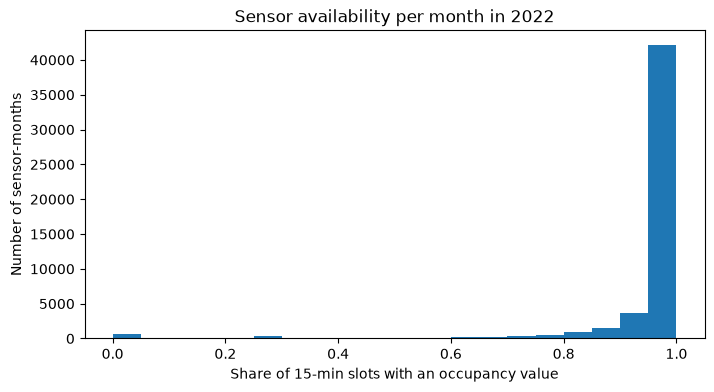

In [29]:
available_share_2022 = point_month_availability.filter(
    pl.col("month").str.starts_with("2022")
)["available_share"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(available_share_2022, bins=20)
ax.set(
    title="Point availability per month in 2022",
    xlabel="Share of 15-min slots with an occupancy value",
    ylabel="Number of point-months",
)
plt.show()

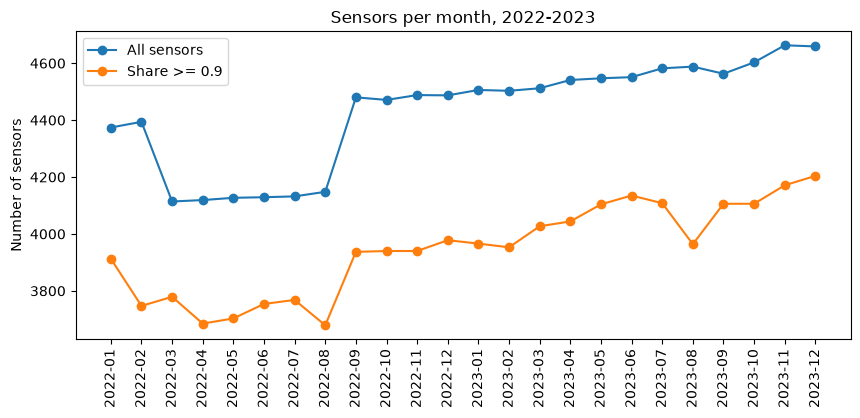

In [ ]:
points_per_month = (
    point_month_availability.group_by("month")
    .agg(
        all_points=pl.len(),
        reliable_points=(pl.col("available_share") >= 0.9).sum(),
    )
    .sort("month")
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    points_per_month["month"],
    points_per_month["all_points"],
    marker="o",
    label="All points",
)
ax.plot(
    points_per_month["month"],
    points_per_month["reliable_points"],
    marker="o",
    label="Available share >= 0.9",
)
ax.set(title="Points per month, 2022-2023", ylabel="Number of points")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.show()

## Step 2: Clock changes (DST rows)
Question: which rows do the summer-time changes break, and how do we find them?

In [31]:
print(calendar.month(2022, 3))
print(calendar.month(2022, 10))
print(calendar.month(2023, 3))
print(calendar.month(2023, 10))

     March 2022
Mo Tu We Th Fr Sa Su
    1  2  3  4  5  6
 7  8  9 10 11 12 13
14 15 16 17 18 19 20
21 22 23 24 25 26 27
28 29 30 31

    October 2022
Mo Tu We Th Fr Sa Su
                1  2
 3  4  5  6  7  8  9
10 11 12 13 14 15 16
17 18 19 20 21 22 23
24 25 26 27 28 29 30
31

     March 2023
Mo Tu We Th Fr Sa Su
       1  2  3  4  5
 6  7  8  9 10 11 12
13 14 15 16 17 18 19
20 21 22 23 24 25 26
27 28 29 30 31

    October 2023
Mo Tu We Th Fr Sa Su
                   1
 2  3  4  5  6  7  8
 9 10 11 12 13 14 15
16 17 18 19 20 21 22
23 24 25 26 27 28 29
30 31



In [32]:
DAYS_TO_COMPARE = {
    "normal Sunday": date(2022, 3, 20),
    "spring change": date(2022, 3, 27),
    "autumn change": date(2022, 10, 30),
}

for label, day in DAYS_TO_COMPARE.items():
    month_file = INTERIM_DATA_DIR / f"{day:%Y-%m}.parquet"
    per_point = (
        pl.read_parquet(month_file, columns=["id", "fecha", "tipo_elem", "periodo_integracion"])
        .filter(pl.col("tipo_elem") == URB, pl.col("fecha").dt.date() == day)
        .group_by("id")
        .agg(rows_that_day=pl.len(), samples_that_day=pl.col("periodo_integracion").sum())
    )
    print(
        f"{label:14} {day} rows: {per_point['rows_that_day'].mode().to_list()}"
        f" samples: {per_point['samples_that_day'].mode().to_list()} points: {per_point.height}"
    )

normal Sunday  2022-03-20 rows: [96] samples: [1440] points: 3940
spring change  2022-03-27 rows: [93] samples: [1378] points: 3946
autumn change  2022-10-30 rows: [96] samples: [1500] points: 3930


In [ ]:
DST_DAYS = [date(2022, 3, 27), date(2022, 10, 30), date(2023, 3, 26), date(2023, 10, 29)]

for day in DST_DAYS:
    night_summary = (
        pl.read_parquet(
            INTERIM_DATA_DIR / f"{day:%Y-%m}.parquet",
            columns=["fecha", "tipo_elem", "periodo_integracion"],
        )
        .filter(
            pl.col("tipo_elem") == URB,
            pl.col("fecha").dt.date() == day,
            pl.col("fecha").dt.time().is_between(time(1, 30), time(3, 30)),
        )
        .group_by(pl.col("fecha").dt.time().alias("slot_end_time"))
        .agg(points=pl.len(), typical_samples=pl.col("periodo_integracion").mode().first())
        .sort("slot_end_time")
    )
    print(day)
    print(night_summary)

2022-03-27
shape: (6, 3)
┌──────────┬────────┬─────────┐
│ row_time ┆ points ┆ samples │
│ ---      ┆ ---    ┆ ---     │
│ time     ┆ u32    ┆ i8      │
╞══════════╪════════╪═════════╡
│ 01:30:00 ┆ 3865   ┆ 15      │
│ 01:45:00 ┆ 3868   ┆ 15      │
│ 02:00:00 ┆ 3868   ┆ 14      │
│ 03:00:00 ┆ 3025   ┆ 1       │
│ 03:15:00 ┆ 3872   ┆ 15      │
│ 03:30:00 ┆ 3899   ┆ 15      │
└──────────┴────────┴─────────┘
2022-10-30
shape: (9, 3)
┌──────────┬────────┬─────────┐
│ row_time ┆ points ┆ samples │
│ ---      ┆ ---    ┆ ---     │
│ time     ┆ u32    ┆ i8      │
╞══════════╪════════╪═════════╡
│ 01:30:00 ┆ 3829   ┆ 15      │
│ 01:45:00 ┆ 3821   ┆ 15      │
│ 02:00:00 ┆ 3850   ┆ 16      │
│ 02:15:00 ┆ 3849   ┆ 30      │
│ 02:30:00 ┆ 3848   ┆ 30      │
│ 02:45:00 ┆ 3830   ┆ 30      │
│ 03:00:00 ┆ 3809   ┆ 29      │
│ 03:15:00 ┆ 3723   ┆ 15      │
│ 03:30:00 ┆ 3726   ┆ 15      │
└──────────┴────────┴─────────┘
2023-03-26
shape: (6, 3)
┌──────────┬────────┬─────────┐
│ row_time ┆ points ┆ samples

In [34]:
points_by_samples = (
    pl.read_parquet(
        INTERIM_DATA_DIR / "2022-10.parquet",
        columns=["fecha", "tipo_elem", "periodo_integracion"],
    )
    .filter(
        pl.col("tipo_elem") == URB,
        pl.col("fecha") == datetime(2022, 10, 30, 2, 15),
    )
    ["periodo_integracion"]
    .value_counts(sort=True, name="points")
)
points_by_samples


periodo_integracion,count
i8,u32
30,2445
15,396
28,139
29,137
27,82
…,…
25,12
20,9
17,8


In [35]:
points_by_samples.filter(pl.col("periodo_integracion") <= SAMPLES_FULL)["points"].sum()

878

Found: spring 03:00 rows hold 1 sample (the jump instant); autumn 02:15-03:00 rows hold up to
30 samples (two real slots merged), and even rows with a normal count belong to the repeated hour.
Decision: remove these 10 rows by date and time (DST_ROWS in config.py); keep the 02:00 rows (14/16).

## Step 3: Short slots and k (2022)
Question: are rows with few one-minute samples noisier than nearly complete rows, and from how many
samples on are they reliable? Measured on 2022 only (k rule). Method first tried on one month.

In [45]:
TRIAL_MONTH = "2022-03"

urb_rows = (
    pl.read_parquet(
        INTERIM_DATA_DIR / f"{TRIAL_MONTH}.parquet",
        columns=["id", "fecha", "tipo_elem", "intensidad", "ocupacion","periodo_integracion"],
    )
    .filter(
        pl.col("tipo_elem") == URB,
        ~ pl.col("fecha").is_in(DST_ROWS)
    )
    .sort(pl.col("id", "fecha"))
)
urb_rows.height

11422709

In [46]:
with_neighbours = urb_rows.with_columns(
    prev_slot_end=pl.col("fecha").shift(1).over("id"),
    next_slot_end=pl.col("fecha").shift(-1).over("id"), 
    prev_occupancy=pl.col("ocupacion").shift(1).over("id"),
    next_occupancy=pl.col("ocupacion").shift(-1).over("id"),
    prev_flow=pl.col("intensidad").shift(1).over("id"),
    next_flow=pl.col("intensidad").shift(-1).over("id"),  
    prev_samples=pl.col("periodo_integracion").shift(1).over("id"),
    next_samples=pl.col("periodo_integracion").shift(-1).over("id"),
)

full_neighbour_rows = with_neighbours.filter(
    pl.col("prev_slot_end") == pl.col("fecha") - SLOT,
    pl.col("next_slot_end") == pl.col("fecha") + SLOT,
    pl.col("prev_samples") == SAMPLES_FULL,
    pl.col("next_samples") == SAMPLES_FULL,
)
full_neighbour_rows.height


8080988

In [47]:
full_neighbour_rows = full_neighbour_rows.with_columns(
    neighbour_occupancy=(pl.col("prev_occupancy") + pl.col("next_occupancy"))/2,
).with_columns(
    occupancy_error=pl.col("ocupacion") - pl.col("neighbour_occupancy"),
)

def occupancy_error_by_samples(df):
    return (
        df.group_by("periodo_integracion")
        .agg(
            rows=pl.len(),
            mean_error=pl.col("occupancy_error").mean().round(2),
            mean_abs_error=pl.col("occupancy_error").abs().mean().round(2),
            median_neighbour_occupancy=pl.col("neighbour_occupancy").median(),
        )
        .sort("periodo_integracion")
    )

occupancy_error_by_samples(full_neighbour_rows)

periodo_integracion,rows,mean_error,mean_abs_error,median_neigh
i8,u32,f64,f64,f64
1,189,1.93,3.63,0.5
2,290,2.67,4.02,0.5
3,559,2.52,3.86,0.5
4,1491,0.94,3.63,3.5
5,1143,1.43,2.78,0.5
…,…,…,…,…
11,14316,0.65,2.47,1.5
12,27769,0.55,2.41,1.5
13,67239,0.59,2.63,2.5


In [48]:
occupancy_error_by_samples(
    full_neighbour_rows.filter(pl.col("neighbour_occupancy").is_between(5, 20))
)

periodo_integracion,rows,mean_error,mean_abs_error,median_neigh
i8,u32,f64,f64,f64
1,22,12.75,20.43,8.0
2,32,11.19,17.22,7.75
3,77,12.59,16.41,6.5
4,520,1.4,4.97,7.5
5,135,5.06,9.95,7.5
…,…,…,…,…
11,2372,1.9,6.14,7.5
12,4938,1.81,5.84,8.0
13,15740,1.46,4.89,8.0


In [38]:
help(pl.DataFrame.sort)

Help on function sort in module polars.dataframe.frame:

sort(self, by: 'IntoExpr | Iterable[IntoExpr]', *more_by: 'IntoExpr', descending: 'bool | Sequence[bool]' = False, nulls_last: 'bool | Sequence[bool]' = False, multithreaded: 'bool' = True, maintain_order: 'bool' = False) -> 'DataFrame'
    Sort the dataframe by the given columns.

    Parameters
    ----------
    by
        Column(s) to sort by. Accepts expression input, including selectors. Strings
        are parsed as column names.
    *more_by
        Additional columns to sort by, specified as positional arguments.
    descending
        Sort in descending order. When sorting by multiple columns, can be specified
        per column by passing a sequence of booleans.
    nulls_last
        Place null values last; can specify a single boolean applying to all columns
        or a sequence of booleans for per-column control.
    multithreaded
        Sort using multiple threads.
    maintain_order
        Whether the order sho